# 2. Preparación de los datos

**Proyecto:** Modelo predictivo de consumo de energía eléctrica residencial en Bogotá (TC1/TC2, SUI).
**Entrada:** `dataset_modelo_v4` (109.345.545 registros, 38 columnas), exportado de BigQuery a Parquet.
**Salida:** `dataset_modelo_prep`, conjunto limpio y listo para el modelado.

Las decisiones de este notebook aplican los hallazgos de `1_Calidad de datos.ipynb`
(ver bóveda: *004.4 Calidad de datos dataset_modelo_v4* y *004.6 Consulta dataset_modelo_v4*).

| Sección | Contenido |
|---|---|
| 0 | Librerías y parámetros |
| 1 | Carga de datos |
| 2 | Limpieza de registros |
| 3 | Eliminación de columnas sin valor |
| 4 | Tratamiento de valores extremos en las características |
| 5 | Variables de calendario a partir de las fechas |
| 6 | Tipificación de variables |
| 7 | Interrelación entre variables |
| 8 | Reducción y agrupación de variables |
| 9 | Conjunto final y exportación |

## 0. Librerías y parámetros

In [1]:
import os
import glob
import shutil
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import dask
import dask.dataframe as dd
import matplotlib.pyplot as plt
import seaborn as sns
import holidays
from google.colab import drive

import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:,.2f}'.format)
sns.set_theme(style='whitegrid')

Parámetros de limpieza. Se definen una sola vez para que cualquier ajuste se haga aquí y no dentro de las celdas.

- `UMBRAL_KWH_DIA`: límite físico tentativo para un hogar (100 kWh/día ≈ 3.000 kWh/mes).
- `DIAS_MIN` / `DIAS_MAX`: rango aceptado de días facturados.
- `PERIODO_BENCH_INVALIDO`: mes en que la línea base llegó en cero para casi todos los usuarios.

In [2]:
UMBRAL_KWH_DIA = 100
DIAS_MIN, DIAS_MAX = 20, 40
PERIODO_BENCH_INVALIDO = pd.Timestamp('2023-09-01')
FRAC_MUESTRA = 0.005          # muestra para gráficas (~500 mil registros)
SEMILLA = 42

DRIVE_ORIGEN = '/content/drive/MyDrive/Superintendencia/dataset_modelo_v4'
LOCAL_ORIGEN = './dataset_modelo_v4'
DRIVE_SALIDA = '/content/drive/MyDrive/Superintendencia/dataset_modelo_prep'
DRIVE_FIGURAS = '/content/drive/MyDrive/Superintendencia/Distribución Datos/Preparación'

Funciones auxiliares cortas que se reutilizan en el notebook.

In [3]:
def guardar_figura(fig, nombre):
    os.makedirs(DRIVE_FIGURAS, exist_ok=True)
    fig.savefig(os.path.join(DRIVE_FIGURAS, f'{nombre}.png'), dpi=150, bbox_inches='tight')

def copiar(ruta):
    destino = os.path.join(LOCAL_ORIGEN, os.path.basename(ruta))
    if not os.path.exists(destino):
        shutil.copy2(ruta, destino)

In [4]:
bitacora = []   # registro de filas tras cada paso de limpieza

def registrar(paso, ddf):
    n = len(ddf)
    bitacora.append({'paso': paso, 'registros': n})
    print(f'{paso}: {n:,} registros')

## 1. Carga de datos

In [5]:
drive.mount('/content/drive')
os.makedirs(LOCAL_ORIGEN, exist_ok=True)
archivos = glob.glob(os.path.join(DRIVE_ORIGEN, '*.parquet'))
print(f'Archivos en Drive: {len(archivos)}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archivos en Drive: 1281


In [6]:
with ThreadPoolExecutor(max_workers=12) as ex:
    list(ex.map(copiar, archivos))
print('Copia local terminada')

Copia local terminada


In [7]:
df = dd.read_parquet(f'{LOCAL_ORIGEN}/*.parquet')
print(f'Columnas: {len(df.columns)}')
df.dtypes

Columnas: 38


,0
PERIODO,date32[day][pyarrow]
MES,int64
NIU_USUARIO,string[pyarrow]
ID_MERCADO,int64
COD_CIRCUITO_LINEA,string[pyarrow]
COD_TRANSFORMADOR,string[pyarrow]
DANE_NIU,int64
UBICACION,int64
ESTRATO_SECTOR,int64
NIVEL_TENSION,int64


In [8]:
registrar('0. Conjunto original (v4)', df)

0. Conjunto original (v4): 109,345,545 registros


## 2. Limpieza de registros

Los filtros se aplican uno por uno y se registra cuántos registros quedan después de cada paso.

### 2.1 Registros de nivel de tensión 2 y autogeneradores
El consumo de un autogenerador es neto de su generación y el nivel 2 no es típico de un hogar.

In [9]:
df = df[(df['NIVEL_TENSION'] == 1) & (df['AUTOGENERADOR'] == 3)]
registrar('1. Solo nivel 1 y no autogeneradores', df)

1. Solo nivel 1 y no autogeneradores: 109,339,456 registros


### 2.2 Usuarios sin medidor
Su consumo no proviene de una medición (752 registros). Además se corrige la codificación de `TIPO_MEDIDOR`.

In [10]:
mapa_medidor = {'ElectrÃ³nico': 'Electrónico', 'ElectromecÃ¡nico': 'Electromecánico'}
df['TIPO_MEDIDOR'] = df['TIPO_MEDIDOR'].replace(mapa_medidor)
df = df[df['TIPO_MEDIDOR'] != 'Usuario sin medidor']
registrar('2. Sin usuarios sin medidor', df)

2. Sin usuarios sin medidor: 109,338,704 registros


### 2.3 Días facturados atípicos
Periodos muy cortos o muy largos distorsionan el consumo diario.

In [11]:
df = df[df['DIAS_FACTURADOS'].between(DIAS_MIN, DIAS_MAX)]
registrar(f'3. Días facturados entre {DIAS_MIN} y {DIAS_MAX}', df)

3. Días facturados entre 20 y 40: 109,300,193 registros


### 2.4 Consumo diario extremo en el objetivo
Valores por encima de `UMBRAL_KWH_DIA` son físicamente improbables para un hogar
(máximo observado: 39.427 kWh/día). Se eliminan.

In [12]:
df = df[df['KWH_DIA'] <= UMBRAL_KWH_DIA]
registrar(f'4. KWH_DIA <= {UMBRAL_KWH_DIA}', df)

4. KWH_DIA <= 100: 109,200,613 registros


### 2.5 Resumen de la limpieza de registros

In [13]:
tabla_limpieza = pd.DataFrame(bitacora)
tabla_limpieza['eliminados'] = -tabla_limpieza['registros'].diff().fillna(0).astype(int)
tabla_limpieza['% conservado'] = tabla_limpieza['registros'] / tabla_limpieza['registros'].iloc[0] * 100
tabla_limpieza

,paso,registros,eliminados,% conservado
0,0. Conjunto original (v4),109345545,0,100.00
1,1. Solo nivel 1 y no autogeneradores,109339456,6089,99.99
2,2. Sin usuarios sin medidor,109338704,752,99.99
3,3. Días facturados entre 20 y 40,109300193,38511,99.96
4,4. KWH_DIA <= 100,109200613,99580,99.87


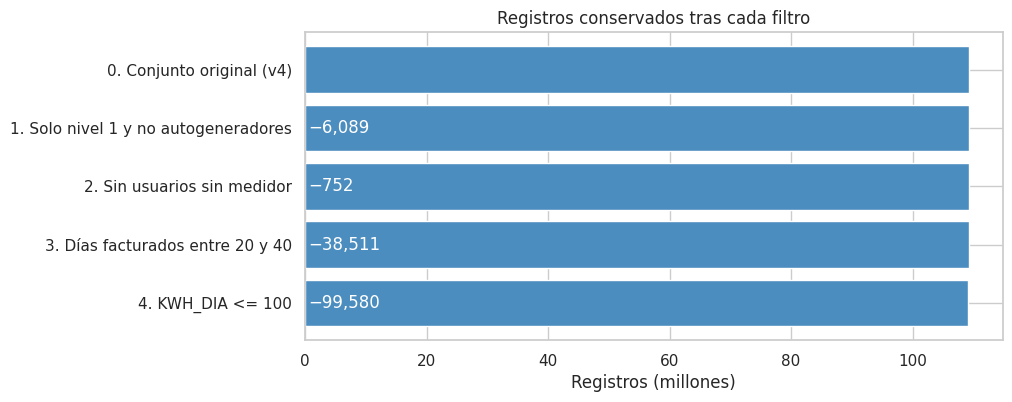

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tabla_limpieza['paso'][::-1], tabla_limpieza['registros'][::-1] / 1e6, color='#4C8DBF')
for i, v in enumerate(tabla_limpieza['eliminados'][::-1]):
    ax.text(0.5, i, f'−{v:,}' if v else '', va='center', color='white')
ax.set_xlabel('Registros (millones)')
ax.set_title('Registros conservados tras cada filtro')
guardar_figura(fig, '02_embudo_limpieza')
plt.show()

## 3. Eliminación de columnas sin valor

Se eliminan las columnas que no aportan información o que introducen fuga de información (*data leakage*).
Cada grupo se justifica con lo observado en la calidad de datos.

### 3.1 Columnas constantes o casi constantes
`ID_MERCADO`, `DANE_NIU` y `TIPO_CONEXION` tienen un único valor (100 %).
`NIVEL_TENSION` `AUTOGENERADOR` y `UBICACION` (casi todo código 2) se verifican antes de decidir.

In [15]:
casi_constantes = ['NIVEL_TENSION', 'UBICACION', 'AUTOGENERADOR']
conteos = dask.compute(*[df[c].value_counts() for c in casi_constantes])
for c, s in zip(casi_constantes, conteos):
    print(f'{c}:\n{(s / s.sum() * 100).round(4).to_string()}\n')

NIVEL_TENSION:
NIVEL_TENSION
1   100.00

UBICACION:
UBICACION
2   99.36
3    0.03
1    0.61

AUTOGENERADOR:
AUTOGENERADOR
3   100.00



**Decisión:** si la categoría dominante supera el 99 %, la variable se elimina por baja varianza.
Los registros minoritarios de `NIVEL_TENSION` y `AUTOGENERADOR` ya se eliminaron en la sección 2, por lo que ambas columnas quedan constantes.

In [16]:
cols_constantes = ['ID_MERCADO', 'DANE_NIU', 'TIPO_CONEXION', 'NIVEL_TENSION', 'AUTOGENERADOR']
ubic_dominante = conteos[1].max() / conteos[1].sum()
if ubic_dominante > 0.99:
    cols_constantes.append('UBICACION')
print(cols_constantes)

['ID_MERCADO', 'DANE_NIU', 'TIPO_CONEXION', 'NIVEL_TENSION', 'AUTOGENERADOR', 'UBICACION']


### 3.2 `CONS_SUBSIST`
Es texto. En Bogotá el consumo de subsistencia depende del estrato, por lo que puede ser redundante con `ESTRATO_SECTOR`.

In [17]:
df.groupby(['ESTRATO_SECTOR', 'CONS_SUBSIST']).size().compute().unstack(fill_value=0)

CONS_SUBSIST,130 kWh mes para alturas iguales o superiores a 1.000 metros sobre el nivel del mar,173 kWh mes para alturas inferiores a 1.000 metros sobre e l nivel del mar,"Cuando se refiera a usuarios de estratos 4, 5, 6 y no residenciales"
ESTRATO_SECTOR,,,
1,8256140,265,91066
2,36647798,1295,505792
3,38165783,2044,752001
4,11402,5,15694187
5,7,1,5098011
6,33,51,3974732


**Decisión:** si cada estrato tiene un único valor de `CONS_SUBSIST`, la columna es redundante con el estrato y se elimina.

In [18]:
cols_redundantes = ['CONS_SUBSIST']

### 3.3 Variables con fuga de información o contemporáneas al objetivo
- `CONSUMO_KWH`: el objetivo es `CONSUMO_KWH / DIAS_FACTURADOS` (fuga directa).
- `ENE_EXPORT`, `CONS_RECUP`, `DIAS_MORA`: se registran en el mismo periodo de la factura; además son casi siempre 0.
- `NRO_FAMILIAS`: 0 en el 99,99 % de los registros.

`DIAS_MORA` rezagada (t−1) podría servir como proxy de estrés económico; queda pendiente para una `v5` en BigQuery.

In [19]:
cols_fuga = ['CONSUMO_KWH', 'ENE_EXPORT', 'CONS_RECUP', 'DIAS_MORA', 'NRO_FAMILIAS']

### 3.4 Variables no confiables
- `CAMBIO_MEDIDOR` (~4 % de los meses) y `MESES_DESDE_CAMBIO`: dependen de `TIPO_MEDIDOR`, que oscila entre meses en TC2.
Las fechas `FECHA_LECTURA` y `FECHA_FACTURA` **no se eliminan aquí**: en la sección 5 se convierten en variables de calendario.

In [20]:
cols_no_confiables = ['CAMBIO_MEDIDOR', 'MESES_DESDE_CAMBIO']

### 3.5 Resumen y eliminación

In [21]:
grupos = {
    'Constantes / baja varianza': cols_constantes,
    'Redundantes': cols_redundantes,
    'Fuga de información': cols_fuga,
    'No confiables': cols_no_confiables,
}
resumen_cols = pd.DataFrame([(g, c) for g, cs in grupos.items() for c in cs],
                            columns=['motivo', 'columna'])
resumen_cols

,motivo,columna
0,Constantes / baja varianza,ID_MERCADO
1,Constantes / baja varianza,DANE_NIU
2,Constantes / baja varianza,TIPO_CONEXION
3,Constantes / baja varianza,NIVEL_TENSION
4,Constantes / baja varianza,AUTOGENERADOR
5,Constantes / baja varianza,UBICACION
6,Redundantes,CONS_SUBSIST
7,Fuga de información,CONSUMO_KWH
8,Fuga de información,ENE_EXPORT
9,Fuga de información,CONS_RECUP


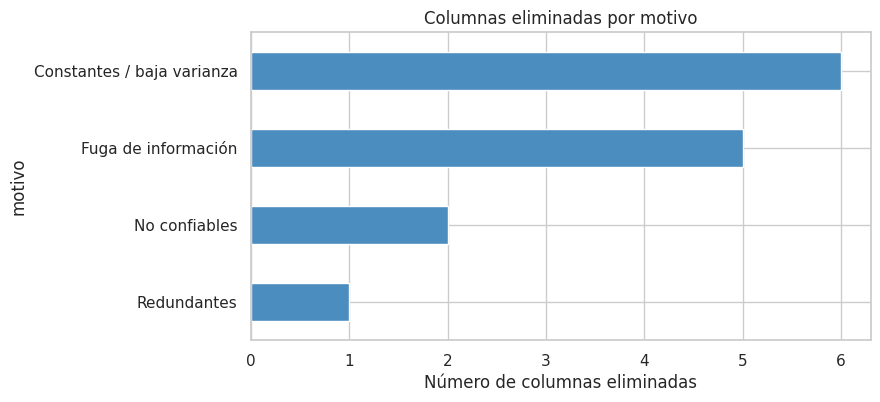

In [22]:
fig, ax = plt.subplots(figsize=(8, 4))
resumen_cols['motivo'].value_counts().sort_values().plot.barh(ax=ax, color='#4C8DBF')
ax.set_xlabel('Número de columnas eliminadas')
ax.set_title('Columnas eliminadas por motivo')
guardar_figura(fig, '01_columnas_eliminadas')
plt.show()

In [23]:
cols_eliminar = resumen_cols['columna'].tolist()
df = df.drop(columns=cols_eliminar)
print(f'Columnas restantes ({len(df.columns)}):')
print(list(df.columns))

Columnas restantes (24):
['PERIODO', 'MES', 'NIU_USUARIO', 'COD_CIRCUITO_LINEA', 'COD_TRANSFORMADOR', 'ESTRATO_SECTOR', 'TIPO_MEDIDOR', 'DIAS_FACTURADOS', 'PROM_SEM_BENCHMARK', 'FECHA_LECTURA', 'FECHA_FACTURA', 'KWH_DIA', 'CAMBIO_TRAFO', 'CAMBIO_ESTRATO', 'KWH_DIA_LAG1', 'KWH_DIA_LAG2', 'KWH_DIA_LAG3', 'KWH_DIA_LAG12', 'KWH_DIA_MM3', 'KWH_DIA_MM6', 'KWH_DIA_STD6', 'KWH_DIA_MM12', 'PCT_CEROS_PREVIOS', 'MESES_HIST_12']


## 4. Tratamiento de valores extremos en las características

Los rezagos y medias móviles se calcularon en BigQuery **antes** del filtro de lectura real,
por lo que pueden contener consumos de meses con lectura estimada (máximo de `KWH_DIA_LAG1`: 97.026 kWh/día).
Los valores por encima del umbral físico se reemplazan por nulo: los modelos de árboles los tratan como faltantes.

In [24]:
cols_consumo = ['KWH_DIA_LAG1', 'KWH_DIA_LAG2', 'KWH_DIA_LAG3', 'KWH_DIA_LAG12',
                'KWH_DIA_MM3', 'KWH_DIA_MM6', 'KWH_DIA_MM12']
n_extremos = dask.compute(*[(df[c] > UMBRAL_KWH_DIA).sum() for c in cols_consumo])
pd.Series(n_extremos, index=cols_consumo, name='valores > umbral')

,valores > umbral
KWH_DIA_LAG1,9583
KWH_DIA_LAG2,9820
KWH_DIA_LAG3,10488
KWH_DIA_LAG12,11281
KWH_DIA_MM3,7884
KWH_DIA_MM6,7933
KWH_DIA_MM12,8595


In [25]:
for c in cols_consumo:
    df[c] = df[c].where(df[c] <= UMBRAL_KWH_DIA)
df['KWH_DIA_STD6'] = df['KWH_DIA_STD6'].where(df['KWH_DIA_MM6'].notnull())

## 5. Variables de calendario a partir de las fechas

`PERIODO` es el mes de **reporte**, no la ventana real de consumo. La fecha de lectura ubica esa ventana:
el consumo facturado ocurre entre `FECHA_LECTURA − DIAS_FACTURADOS` y `FECHA_LECTURA`.
La lectura sigue un cronograma por ciclo, así que la fecha **planeada** se conoce antes de leer;
aquí se usa la fecha real como aproximación de la planeada (supuesto a validar con el comercializador).

`FECHA_FACTURA` es posterior al consumo; solo se usa para medir el retraso de facturación y decidir si aporta.

In [26]:
df['F_LECTURA'] = dd.to_datetime(df['FECHA_LECTURA'], format='%d/%m/%y', errors='coerce')
df['F_FACTURA'] = dd.to_datetime(df['FECHA_FACTURA'], format='%d/%m/%y', errors='coerce')

### 5.1 Validación de las fechas

In [27]:
chequeos = dask.compute(df['F_LECTURA'].isnull().mean(),
                        df['F_FACTURA'].isnull().mean(),
                        (df['F_FACTURA'] < df['F_LECTURA']).mean(),
                        df['F_LECTURA'].min(), df['F_LECTURA'].max())
pd.Series(chequeos, index=['% lectura no convertible', '% factura no convertible',
                           '% factura antes de lectura', 'lectura mínima', 'lectura máxima'])

,0
% lectura no convertible,0.00
% factura no convertible,0.00
% factura antes de lectura,0.00
lectura mínima,2021-12-28 00:00:00
lectura máxima,2025-12-31 00:00:00


### 5.2 Variables derivadas
| Variable | Descripción |
|---|---|
| `DIA_LECTURA` | Día del mes de la lectura (aproxima el ciclo de lectura) |
| `MES_CONSUMO` | Mes del punto medio de la ventana de consumo |
| `DIAS_FIN_SEMANA` | Sábados y domingos dentro de la ventana |
| `DIAS_FESTIVOS` | Festivos de Colombia en días hábiles dentro de la ventana |
| `RETRASO_FACTURA` | Días entre la lectura y la expedición de la factura |

In [28]:
df['DIA_LECTURA'] = df['F_LECTURA'].dt.day
medio = df['F_LECTURA'] - dd.to_timedelta(df['DIAS_FACTURADOS'] / 2, unit='D')
df['MES_CONSUMO'] = medio.dt.month
df['RETRASO_FACTURA'] = (df['F_FACTURA'] - df['F_LECTURA']).dt.days

In [29]:
FESTIVOS = np.array(sorted(holidays.Colombia(years=range(2021, 2026))), dtype='datetime64[D]')

def contar_dias(p):
    fin = p['F_LECTURA'].values.astype('datetime64[D]')
    ini = fin - p['DIAS_FACTURADOS'].values.astype('timedelta64[D]')
    ok = ~np.isnat(fin)
    lab = np.full(len(p), np.nan); hab = np.full(len(p), np.nan)
    lab[ok] = np.busday_count(ini[ok], fin[ok])
    hab[ok] = np.busday_count(ini[ok], fin[ok], holidays=FESTIVOS)
    p['DIAS_FIN_SEMANA'] = p['DIAS_FACTURADOS'] - lab
    p['DIAS_FESTIVOS'] = lab - hab
    return p

df = df.map_partitions(contar_dias)

In [30]:
df = df.drop(columns=['FECHA_LECTURA', 'FECHA_FACTURA', 'F_LECTURA', 'F_FACTURA'])
cols_calendario = ['DIA_LECTURA', 'DIAS_FIN_SEMANA', 'DIAS_FESTIVOS', 'RETRASO_FACTURA']
df[cols_calendario + ['MES_CONSUMO']].head()

,DIA_LECTURA,DIAS_FIN_SEMANA,DIAS_FESTIVOS,RETRASO_FACTURA,MES_CONSUMO
0,28,8.00,2.00,5,7
1,3,8.00,1.00,5,7
2,1,10.00,2.00,3,7
3,9,8.00,1.00,3,7
4,29,8.00,2.00,5,7


## 6. Tipificación de variables y línea base

- Las variables codificadas como enteros que son categóricas se convierten a `category`.
- `COD_TRANSFORMADOR` y `COD_CIRCUITO_LINEA` se conservan: su codificación (p. ej., *target encoding*) debe ajustarse
  solo con el conjunto de entrenamiento, por lo que se hace en el notebook de modelado.
- Se crea `BENCH_KWH_DIA` (línea base en kWh/día) y la bandera `BENCH_VALIDO`, que excluye el mes con la línea base en cero.

In [31]:
cols_categoricas = ['ESTRATO_SECTOR', 'TIPO_MEDIDOR', 'MES', 'MES_CONSUMO', 'COD_TRANSFORMADOR', 'COD_CIRCUITO_LINEA']
if 'UBICACION' in df.columns:
    cols_categoricas.append('UBICACION')
for c in cols_categoricas:
    df[c] = df[c].astype(str).astype('category')

In [32]:
df['BENCH_KWH_DIA'] = df['PROM_SEM_BENCHMARK'] / df['DIAS_FACTURADOS']
df['BENCH_VALIDO'] = (dd.to_datetime(df['PERIODO']) != PERIODO_BENCH_INVALIDO).astype('int8')
df.dtypes

,0
PERIODO,date32[day][pyarrow]
MES,category
NIU_USUARIO,string[pyarrow]
COD_CIRCUITO_LINEA,category
COD_TRANSFORMADOR,category
ESTRATO_SECTOR,category
TIPO_MEDIDOR,category
DIAS_FACTURADOS,float64
PROM_SEM_BENCHMARK,float64
KWH_DIA,float64


## 7. Interrelación entre variables

Se trabaja sobre una muestra aleatoria para que las gráficas sean rápidas.
El objetivo es identificar qué variables se relacionan con `KWH_DIA` y cuáles son redundantes entre sí.

In [33]:
muestra = df.sample(frac=FRAC_MUESTRA, random_state=SEMILLA).compute()
print(f'Muestra: {len(muestra):,} registros')

: 

### 7.1 Correlación entre variables numéricas (Spearman)
Se usa Spearman porque el consumo es asimétrico y tiene cola larga.

In [ ]:
cols_num = ['KWH_DIA', 'BENCH_KWH_DIA'] + cols_consumo + \
           ['KWH_DIA_STD6', 'PCT_CEROS_PREVIOS', 'MESES_HIST_12', 'DIAS_FACTURADOS'] + cols_calendario
corr = muestra[cols_num].corr(method='spearman')

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax, annot_kws={'size': 8})
ax.set_title('Correlación de Spearman entre variables numéricas')
guardar_figura(fig, '03_correlacion_spearman')
plt.show()

### 7.2 Correlación de cada variable con el objetivo

In [ ]:
corr_obj = corr['KWH_DIA'].drop('KWH_DIA').sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
corr_obj.plot.barh(ax=ax, color=np.where(corr_obj > 0, '#4C8DBF', '#C0392B'))
ax.set_xlabel('Correlación de Spearman con KWH_DIA')
ax.set_title('Relación de cada variable con el consumo diario')
guardar_figura(fig, '04_correlacion_objetivo')
plt.show()

### 7.3 Redundancia entre características
Pares con correlación mayor a 0,95 aportan casi la misma información.

In [ ]:
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pares[pares.abs() > 0.95].sort_values(ascending=False).to_frame('rho')

### 7.4 Consumo del mes anterior frente al consumo actual

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
hb = ax.hexbin(muestra['KWH_DIA_LAG1'], muestra['KWH_DIA'], gridsize=60,
               extent=(0, 25, 0, 25), bins='log', cmap='viridis', mincnt=1)
ax.plot([0, 25], [0, 25], 'r--', lw=1)
ax.set_xlabel('KWH_DIA_LAG1 (kWh/día)')
ax.set_ylabel('KWH_DIA (kWh/día)')
ax.set_title('Persistencia del consumo mes a mes')
fig.colorbar(hb, label='log10(registros)')
guardar_figura(fig, '05_lag1_vs_objetivo')
plt.show()

### 7.5 Consumo por estrato

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=muestra, x='ESTRATO_SECTOR', y='KWH_DIA', showfliers=False, color='#4C8DBF', ax=ax)
ax.set_xlabel('Estrato')
ax.set_ylabel('KWH_DIA (kWh/día)')
ax.set_title('Consumo diario por estrato (sin atípicos en el gráfico)')
guardar_figura(fig, '06_consumo_estrato')
plt.show()

### 7.6 Consumo por tipo de medidor

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=muestra, x='TIPO_MEDIDOR', y='KWH_DIA', showfliers=False, color='#7FA65A', ax=ax)
ax.set_xlabel('')
ax.set_ylabel('KWH_DIA (kWh/día)')
ax.set_title('Consumo diario por tipo de medidor')
plt.xticks(rotation=20)
guardar_figura(fig, '07_consumo_medidor')
plt.show()

### 7.7 Estacionalidad: consumo medio por mes del año y estrato

In [ ]:
estacional = muestra.groupby(['MES', 'ESTRATO_SECTOR'], observed=True)['KWH_DIA'].mean().unstack()
estacional.index = estacional.index.astype(int)
estacional = estacional.sort_index()

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
estacional.plot(ax=ax, marker='o')
ax.set_xlabel('Mes')
ax.set_ylabel('KWH_DIA medio (kWh/día)')
ax.set_title('Estacionalidad del consumo por estrato')
ax.legend(title='Estrato', ncol=6)
guardar_figura(fig, '08_estacionalidad_estrato')
plt.show()

### 7.8 Meses previos sin consumo y consumo actual

In [ ]:
muestra['GRUPO_CEROS'] = pd.cut(muestra['PCT_CEROS_PREVIOS'], [-0.01, 0, 0.25, 0.5, 0.99, 1],
                                labels=['0', '(0, 0,25]', '(0,25, 0,5]', '(0,5, 1)', '1'])
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=muestra, x='GRUPO_CEROS', y='KWH_DIA', showfliers=False, color='#D68910', ax=ax)
ax.set_xlabel('Proporción de meses en cero (12 meses previos)')
ax.set_ylabel('KWH_DIA (kWh/día)')
ax.set_title('Historia de desocupación y consumo actual')
guardar_figura(fig, '09_ceros_previos')
plt.show()

### 7.9 Cardinalidad espacial: usuarios por transformador

In [ ]:
usuarios_trafo = df[['COD_TRANSFORMADOR', 'NIU_USUARIO']].astype(str).groupby('COD_TRANSFORMADOR')['NIU_USUARIO'].nunique().compute()
usuarios_trafo.describe()

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(usuarios_trafo.clip(upper=usuarios_trafo.quantile(0.99)), bins=60, color='#4C8DBF')
ax.set_xlabel('Usuarios distintos por transformador (recortado en p99)')
ax.set_ylabel('Transformadores')
ax.set_title('Tamaño de los grupos por transformador')
guardar_figura(fig, '10_usuarios_transformador')
plt.show()

### 7.10 Calendario de la ventana de consumo\n¿Los festivos, los fines de semana o el ciclo de lectura se relacionan con el consumo?

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=muestra, x='DIAS_FESTIVOS', y='KWH_DIA', showfliers=False, color='#4C8DBF', ax=axes[0])
axes[0].set_title('Consumo diario según festivos en la ventana')
muestra.groupby('DIA_LECTURA')['KWH_DIA'].mean().plot(ax=axes[1], marker='o', color='#C0392B')
axes[1].set_title('Consumo diario medio según día de lectura')
axes[1].set_ylabel('KWH_DIA (kWh/día)')
guardar_figura(fig, '11_calendario_consumo')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(muestra['RETRASO_FACTURA'].clip(-5, 30), bins=36, color='#7FA65A')
ax.set_xlabel('Días entre lectura y factura (recortado en [−5, 30])')
ax.set_ylabel('Registros')
ax.set_title('Retraso de facturación')
guardar_figura(fig, '12_retraso_factura')
plt.show()

## 8. Reducción y agrupación de variables

Los rezagos y las medias móviles describen la misma historia de consumo y están muy correlacionados.
Se evalúa cuánta información independiente contienen (PCA) y se agrupan en pocas variables interpretables,
en lugar de usar componentes principales, que dificultarían explicar el modelo.

### 8.1 PCA del bloque de consumo histórico
Solo como diagnóstico: cuántas dimensiones explican la varianza del bloque.

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

bloque = muestra[cols_consumo + ['KWH_DIA_STD6']].dropna()
pca = PCA().fit(StandardScaler().fit_transform(bloque))
var_acum = np.cumsum(pca.explained_variance_ratio_)
pd.Series(var_acum, index=[f'CP{i+1}' for i in range(len(var_acum))], name='varianza acumulada')

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, len(var_acum) + 1), pca.explained_variance_ratio_, color='#4C8DBF', label='Individual')
ax.plot(range(1, len(var_acum) + 1), var_acum, 'o-', color='#C0392B', label='Acumulada')
ax.axhline(0.95, ls='--', color='grey', lw=1)
ax.set_xlabel('Componente principal')
ax.set_ylabel('Varianza explicada')
ax.set_title('PCA del bloque de consumo histórico')
ax.legend()
guardar_figura(fig, '13_pca_consumo')
plt.show()

In [ ]:
cargas = pd.DataFrame(pca.components_[:3].T, index=bloque.columns, columns=['CP1', 'CP2', 'CP3'])
cargas.round(2)

### 8.2 Variables agrupadas
A partir del bloque histórico se construyen variables que resumen nivel, tendencia, estacionalidad y volatilidad:

| Variable | Fórmula | Interpretación |
|---|---|---|
| `NIVEL_12` | `KWH_DIA_MM12` | Nivel de consumo del último año |
| `TENDENCIA` | `KWH_DIA_MM3 − KWH_DIA_MM12` | Consumo reciente frente al anual |
| `ESTACIONAL` | `KWH_DIA_LAG12 − KWH_DIA_MM12` | Desvío del mismo mes del año anterior |
| `CV6` | `KWH_DIA_STD6 / KWH_DIA_MM6` | Volatilidad relativa |

In [ ]:
def agrupar(d):
    d['NIVEL_12'] = d['KWH_DIA_MM12']
    d['TENDENCIA'] = d['KWH_DIA_MM3'] - d['KWH_DIA_MM12']
    d['ESTACIONAL'] = d['KWH_DIA_LAG12'] - d['KWH_DIA_MM12']
    d['CV6'] = (d['KWH_DIA_STD6'] / d['KWH_DIA_MM6']).where(d['KWH_DIA_MM6'] > 0)
    return d

df = agrupar(df)
muestra = agrupar(muestra)

### 8.3 Selección automática por redundancia
De cada par con |ρ| > 0,95 se conserva la variable más correlacionada con el objetivo.

In [ ]:
candidatas = ['KWH_DIA_LAG1', 'KWH_DIA_LAG2', 'KWH_DIA_LAG3', 'KWH_DIA_LAG12', 'KWH_DIA_MM3', 'KWH_DIA_MM6',
              'NIVEL_12', 'TENDENCIA', 'ESTACIONAL', 'CV6', 'KWH_DIA_STD6',
              'PCT_CEROS_PREVIOS', 'MESES_HIST_12', 'DIAS_FACTURADOS'] + cols_calendario
corr_c = muestra[candidatas + ['KWH_DIA']].corr(method='spearman')
rel_obj = corr_c['KWH_DIA'].abs()

In [ ]:
descartadas = set()
for a in candidatas:
    for b in candidatas:
        if a < b and abs(corr_c.loc[a, b]) > 0.95 and not {a, b} & descartadas:
            descartadas.add(a if rel_obj[a] < rel_obj[b] else b)
seleccion_num = [c for c in candidatas if c not in descartadas]
print('Descartadas por redundancia:', sorted(descartadas))
print('Numéricas seleccionadas:', seleccion_num)

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(muestra[seleccion_num + ['KWH_DIA']].corr(method='spearman'), annot=True, fmt='.2f',
            cmap='RdBu_r', vmin=-1, vmax=1, ax=ax, annot_kws={'size': 8})
ax.set_title('Correlación de las variables seleccionadas')
guardar_figura(fig, '14_correlacion_seleccion')
plt.show()

## 9. Conjunto final y exportación
El conjunto final contiene llaves, objetivo, línea base, variables categóricas y las numéricas seleccionadas.
Se guarda en Parquet, particionado por año, para el notebook de modelado.

In [ ]:
cols_llave = ['PERIODO', 'NIU_USUARIO']
cols_objetivo = ['KWH_DIA', 'BENCH_KWH_DIA', 'PROM_SEM_BENCHMARK', 'BENCH_VALIDO']
cols_finales = cols_llave + cols_objetivo + cols_categoricas + ['CAMBIO_TRAFO', 'CAMBIO_ESTRATO'] + seleccion_num
df = df[cols_finales]
pd.DataFrame({'columna': cols_finales})

In [ ]:
df['ANIO'] = dd.to_datetime(df['PERIODO']).dt.year
df.to_parquet(DRIVE_SALIDA, partition_on=['ANIO'], write_index=False, overwrite=True)
print(f'Guardado en {DRIVE_SALIDA}')

In [ ]:
final = dd.read_parquet(DRIVE_SALIDA)
print(f'Registros: {len(final):,} | Columnas: {len(final.columns)}')
print(list(final.columns))

## 10. Conclusiones de la preparación

*(Se completa después de ejecutar el notebook en Colab.)*